In [1]:
!pip3 install polars
!pip3 install scikit-learn
!pip3 install altair
!pip3 install seaborn
!pip3 install xgboost
!pip3 install pyarrow


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# welke genre
(gebruik lazy polars)

In [2]:
import polars as pl


In [3]:
df = pl.read_csv("./Spotify_tracks_final.csv")

In [4]:
df.head(5)

,track_name,track_id,album_name,album_id,album_image,album_release_date,album_release_date_precision,artist_name,artist_id,popularity,duration_ms,explicit,preview_url,genre,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,database_shard_id,duration_seconds,duration_minutes
i64,str,str,str,str,str,str,str,str,str,i64,i64,bool,str,str,f64,f64,f64,f64,i64,f64,f64,i64,f64,f64,i64,f64,i64,f64,f64
0,"""Divenire: No. 9, Fly - Intouch…","""5u5scm02d5wN6nWFKuqEUK""","""Discover The Great Classics""","""6HKSdjtjJGtxmeUrkhSCSf""","""https://i.scdn.co/image/ab6761…","""1950""","""year""","""Jeroen van Veen""","""7o7D77HMHvg1sAmtryKoVy""",2,265653,false,"""https://p.scdn.co/mp3-preview/…","""ambient""",0.99,0.184,0.0327,0.877,1,0.0996,-28.184,0,0.0366,168.133,3,0.0351,0,265.653,4.42755
1,"""Spiegel im Spiegel - Heaven""","""1wV4SNFEXWawsyjBCGwkiw""","""Discover The Great Classics""","""6HKSdjtjJGtxmeUrkhSCSf""","""https://i.scdn.co/image/ab6761…","""1950""","""year""","""Jeroen van Veen""","""7o7D77HMHvg1sAmtryKoVy""",0,349120,false,"""https://p.scdn.co/mp3-preview/…","""ambient""",0.985,0.25,0.0148,0.971,5,0.0669,-30.646,1,0.0375,136.864,5,0.0394,0,349.12,5.818667
2,"""Truman Sleeps - The Trumanshow""","""4gYub3T80gNfU9F4Df98AR""","""Discover The Great Classics""","""6HKSdjtjJGtxmeUrkhSCSf""","""https://i.scdn.co/image/ab6761…","""1950""","""year""","""Jeroen van Veen""","""7o7D77HMHvg1sAmtryKoVy""",1,128039,false,"""https://p.scdn.co/mp3-preview/…","""ambient""",0.993,0.269,0.0211,0.883,5,0.139,-24.62,0,0.0395,69.487,4,0.0411,0,128.039,2.133983
3,"""The Heart Askes Pleasure First…","""6sXRgSAQsySTM7kH1pM07Y""","""Discover The Great Classics""","""6HKSdjtjJGtxmeUrkhSCSf""","""https://i.scdn.co/image/ab6761…","""1950""","""year""","""Jeroen van Veen""","""7o7D77HMHvg1sAmtryKoVy""",0,190960,false,"""https://p.scdn.co/mp3-preview/…","""ambient""",0.995,0.23,0.138,0.885,4,0.101,-19.591,0,0.0371,165.197,3,0.171,0,190.96,3.182667
4,"""3 Gymnopédies: I. Lent et doul…","""7Eytd0e0mNFiSWIE132H76""","""Discover The Great Classics""","""6HKSdjtjJGtxmeUrkhSCSf""","""https://i.scdn.co/image/ab6761…","""1950""","""year""","""Jeroen van Veen""","""7o7D77HMHvg1sAmtryKoVy""",4,338933,false,"""https://p.scdn.co/mp3-preview/…","""ambient""",0.995,0.611,0.00162,0.967,7,0.0817,-37.782,1,0.286,134.237,3,0.508,0,338.933,5.648883


In [5]:
df.select(pl.col("album_release_date_precision").unique())

album_release_date_precision
str
"""day"""
"""month"""
"""year"""


In [6]:
df.filter(pl.col("genre").str.contains("japanese"))

,track_name,track_id,album_name,album_id,album_image,album_release_date,album_release_date_precision,artist_name,artist_id,popularity,duration_ms,explicit,preview_url,genre,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,database_shard_id,duration_seconds,duration_minutes
i64,str,str,str,str,str,str,str,str,str,i64,i64,bool,str,str,f64,f64,f64,f64,i64,f64,f64,i64,f64,f64,i64,f64,i64,f64,f64


# filteren op naam niet op id

In [7]:
artist_names = (
    df
    .select("artist_name")
    .unique()

)

artist_names = artist_names.with_columns(
    pl.col("artist_name")
    .str.to_lowercase()
    .str.strip_chars()
    .alias("normalized_name")
)
duplicates = (
    artist_names
    .group_by("normalized_name")
    .agg(
        pl.col("artist_name").unique().alias("names")
    ).sort("names", descending=True)
    .filter(pl.col("names").list.len() > 1)
)

duplicates

normalized_name,names
str,list[str]
"""side effects""","[""side effects"", ""Side Effects""]"
"""luz""","[""luz"", ""Luz""]"
"""ikon""","[""iKON"", ""Ikon""]"
"""freestyle""","[""freestyle"", ""Freestyle""]"
"""disrupt""","[""disrupt"", ""Disrupt""]"
…,…
"""blaze""","[""BLAZE"", ""Blaze""]"
"""aurora""","[""AURORA"", ""Aurora""]"
"""antena""","[""ANTENA"", ""Antena""]"


In [8]:
duplicates = (
    df
    .group_by("artist_name")
    .agg(
        pl.col("artist_id").n_unique().alias("n_ids"),
        pl.col("artist_id").unique().alias("artist_ids"),
    )
    .filter(pl.col("n_ids") > 1)
    .sort("n_ids", descending=True)

)
duplicates

artist_name,n_ids,artist_ids
str,u32,list[str]
"""Dave""",3,"[""39Fh4OTce0hxKCiuyB21dg"", ""6Ip8FS7vWT1uKkJSweANQK"", ""20DyMdyPK3G4kExwh0XMHD""]"
"""Genocide""",3,"[""07G5ym8Y8aJb6hHmgUounA"", ""1rvYUhkwLtzqnRY8kOcYv3"", ""0E01oYSi6EDH9NVb8BzTHt""]"
"""Avalon""",3,"[""6wC4LAODjyPeHr10lcrO6x"", ""4rulVipLmUL2Mg67SIUmCO"", ""0SFwBkGokPRtTX212zO7xo""]"
"""Logic""",3,"[""1BF6z9EIGGoPViPON57eGC"", ""6rpTmAVssi39dK1wX5ncZT"", ""4xRYI6VqpkE3UwrDrAZL8L""]"
"""Erika""",3,"[""4zoUnBzcHHhQsZFDdveLzX"", ""0BOibkUD42LDBqdUuhoZrE"", ""5N9lpSK39RSCDkLxPNH4KC""]"
…,…,…
"""Lock Up""",2,"[""630pTnkYgMsGZ1Te7M9yyq"", ""0AKZrsOYW77C7QW1jzdhNX""]"
"""Steve Lacy""",2,"[""1BEsuwAkTQMG50TeHB5qny"", ""57vWImR43h4CaDao012Ofp""]"
"""Stallion""",2,"[""4H7l564NLNANlnd5rIrJjy"", ""43lyRnDDkv8BtdVHsfZsAE""]"


# basic cleanup
verwijderen van irrelevante kolommen

In [9]:
def columns_cleanup(df: pl.LazyFrame) -> pl.LazyFrame:
    return (df.drop([
        "track_id",
        "album_image",
        "preview_url",
        "album_name",
        "track_name",
        "artist_name",
        "duration_minutes", # duration seconds says thesame
        "duration_seconds",
        "database_shard_id"
        
    ])
    # converteren van year enz naar een timeformat
        .with_columns(
            pl.when(pl.col("album_release_date_precision") == "year")
            .then(pl.col("album_release_date") + "-01-01")
            .when(pl.col("album_release_date_precision") == "month")
            .then(pl.col("album_release_date") + "-01")
            .otherwise(pl.col("album_release_date"))
            .str.to_date(strict=False)
            .alias("album_release_date")
        )
        .drop("album_release_date_precision")

    # removing songwriter because not enough data
    .filter(pl.col("genre")!="songwriter")

    .with_columns(pl.col("explicit").cast(pl.Int8))
    
    # lower casing every artist name
)


def feature_engineering(df: pl.LazyFrame) -> pl.LazyFrame:
    drop_labels = [
        "british",
        "french",
        "german",
        "spanish",
        "swedish",
        "japanese",
        "iranian",
        "turkish",
        "malay",

        "afrobeat",
        "dubstep",
        "edm",
        "electro",
        "electronic",
        "garage",
        "gospel",
        "industrial",
        "japanese",
        "party",
        "sad",
        "show-tunes",
        "ska",
        "japanese",

        "chill",
        "romance",
        "happy",
        "pop-film",

        "children",
        "kids",
        "disney",


        "anime",
        "j-idol",
        "j-dance",
    ]
    # return year because it may correlate with popularity
    return df.filter(
            ~pl.any_horizontal([
                pl.col("genre").str.to_lowercase().str.contains(label.lower(), literal=True)
                for label in drop_labels
            ])
        )

df = columns_cleanup(df)
df = feature_engineering(df)

print(df["genre"].unique().sort())

shape: (82,)
Series: 'genre' [str]
[
	"acoustic"
	"alt-rock"
	"alternative"
	"ambient"
	"black-metal"
	…
	"tango"
	"techno"
	"trance"
	"trip-hop"
	"world-music"
]


# evaluating number of albums per release year

In [10]:
rock_genres = (
    df
    .filter(pl.col("genre").str.contains("(?i)rock"))
    .group_by("genre")
    .len()
    .sort("len", descending=True)
)

print(rock_genres)

shape: (8, 2)
┌─────────────┬───────┐
│ genre       ┆ len   │
│ ---         ┆ ---   │
│ str         ┆ u32   │
╞═════════════╪═══════╡
│ alt-rock    ┆ 37065 │
│ hard-rock   ┆ 19865 │
│ rock-n-roll ┆ 17749 │
│ j-rock      ┆ 15726 │
│ rockabilly  ┆ 13712 │
│ psych-rock  ┆ 12397 │
│ punk-rock   ┆ 7272  │
│ rock        ┆ 5240  │
└─────────────┴───────┘


In [11]:
number_of_songs_per_year = (
    df
    .sort("album_release_date")
    .group_by_dynamic(
        "album_release_date",
        every="1y"
    )
    .agg(
        pl.len().alias("count")
    )

)

chart= number_of_songs_per_year.plot.line(
    x="album_release_date",
    y="count",
)

chart.show()

alt.Chart(...)

In [12]:
df.select(
    pl.col("genre").n_unique()
).item() # number of genres


82

# hoeveel muziekstukken per genre

In [13]:
n_genres = df.group_by("genre").agg(
    pl.len().alias("count")
).sort(
    "count", descending=True
)


chart = n_genres.plot.bar(
    x="genre",
    y="count",
)

chart.show()


alt.Chart(...)

In [14]:
number_of_genre_count_per_year = (
    df
    .sort("album_release_date")
    .group_by_dynamic(
        "album_release_date",
        every="1y",
        group_by="genre"
    )
    .agg(pl.len().alias("count"))

)
number_of_genre_count_per_year.head(5)

genre,album_release_date,count
str,date,u32
"""dub""",1960-01-01,1
"""dub""",1962-01-01,2
"""dub""",1963-01-01,11
"""dub""",1964-01-01,33
"""dub""",1965-01-01,17


In [15]:


top_genres = (
    number_of_genre_count_per_year
    .group_by("genre")
    .agg(
        pl.col("count").sum().alias("total")
    )
    .sort("total", descending=True)
    .head(10)
)

plot_data = number_of_genre_count_per_year.filter(
    pl.col("genre").is_in(top_genres["genre"].implode())
)

chart = plot_data.plot.line(
    x="album_release_date",
    y="count",
    color="genre",
)

chart.show()


alt.Chart(...)

# number of genres per artist

In [16]:
n_genres_per_artist = (df.group_by(pl.col("artist_id")).agg(
    pl.col("genre").n_unique()
).sort(pl.col("genre"), descending=True)


)

# get the count of artists with different 
n_genres_per_artist.group_by("genre").agg(pl.col("artist_id").count())


genre,artist_id
u32,u32
9,1
8,2
7,13
6,44
5,131
4,558
3,2053
2,7884
1,49216


In [17]:
df.head(5)

,album_id,album_release_date,artist_id,popularity,duration_ms,explicit,genre,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence
i64,str,date,str,i64,i64,i8,str,f64,f64,f64,f64,i64,f64,f64,i64,f64,f64,i64,f64
0,"""6HKSdjtjJGtxmeUrkhSCSf""",1950-01-01,"""7o7D77HMHvg1sAmtryKoVy""",2,265653,0,"""ambient""",0.99,0.184,0.0327,0.877,1,0.0996,-28.184,0,0.0366,168.133,3,0.0351
1,"""6HKSdjtjJGtxmeUrkhSCSf""",1950-01-01,"""7o7D77HMHvg1sAmtryKoVy""",0,349120,0,"""ambient""",0.985,0.25,0.0148,0.971,5,0.0669,-30.646,1,0.0375,136.864,5,0.0394
2,"""6HKSdjtjJGtxmeUrkhSCSf""",1950-01-01,"""7o7D77HMHvg1sAmtryKoVy""",1,128039,0,"""ambient""",0.993,0.269,0.0211,0.883,5,0.139,-24.62,0,0.0395,69.487,4,0.0411
3,"""6HKSdjtjJGtxmeUrkhSCSf""",1950-01-01,"""7o7D77HMHvg1sAmtryKoVy""",0,190960,0,"""ambient""",0.995,0.23,0.138,0.885,4,0.101,-19.591,0,0.0371,165.197,3,0.171
4,"""6HKSdjtjJGtxmeUrkhSCSf""",1950-01-01,"""7o7D77HMHvg1sAmtryKoVy""",4,338933,0,"""ambient""",0.995,0.611,0.00162,0.967,7,0.0817,-37.782,1,0.286,134.237,3,0.508


In [18]:
numeric_cols = [
    name
    for name, dtype in df.collect_schema().items()
    if dtype.is_numeric()
]

corr = (
    df
    .select(numeric_cols)

    .corr()
)

corr

column_0,popularity,duration_ms,explicit,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1.0,0.338941,0.009125,0.141202,-0.239306,0.080982,0.250373,0.06917,0.010892,0.016901,0.270511,-0.064385,0.087115,0.072212,0.040863,-0.147838
0.338941,1.0,-0.038682,0.168979,-0.15961,0.090005,0.116023,-0.148476,0.002758,-0.014073,0.189187,-0.023438,0.00884,0.027432,0.042627,-0.030793
0.009125,-0.038682,1.0,-0.056125,-0.049871,-0.062273,-0.008431,0.181067,0.002875,0.010675,-0.066422,-0.048499,-0.050763,-0.00597,0.016413,-0.177253
0.141202,0.168979,-0.056125,1.0,-0.108771,0.076811,0.131464,-0.092102,0.008246,0.081546,0.118003,-0.028759,0.358997,-0.016738,0.015083,-0.017369
-0.239306,-0.15961,-0.049871,-0.108771,1.0,-0.196691,-0.742736,0.089808,-0.036827,-0.019682,-0.590552,0.071144,0.005076,-0.229969,-0.176173,-0.121046
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
-0.064385,-0.023438,-0.048499,-0.028759,0.071144,-0.042822,-0.060069,-0.064874,-0.155603,0.018211,-0.023529,1.0,-0.028296,-0.001431,-0.016064,0.027873
0.087115,0.00884,-0.050763,0.358997,0.005076,0.094357,0.133606,-0.110644,0.017274,0.273597,0.034772,-0.028296,1.0,-0.028226,-0.033841,0.014972
0.072212,0.027432,-0.00597,-0.016738,-0.229969,-0.021967,0.251713,-0.025481,0.008636,-0.000907,0.216145,-0.001431,-0.028226,1.0,0.019475,0.107336


# machine learning

In [19]:
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
from sklearn.model_selection import train_test_split

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

In [20]:
import polars as pl

genre_mapping = {
    # =========================
    # ROCK
    # =========================
    "alt-rock": "rock",
    "hard-rock": "rock",
    "rock-n-roll": "rock",
    "j-rock": "rock",
    "rockabilly": "rock",
    "psych-rock": "rock",
    "punk-rock": "rock",
    "rock": "rock",
    "alternative": "rock",
    "indie": "rock",
    "indie-pop": "rock",
    "grunge": "rock",
    "punk": "rock",
    "emo": "rock",
    "power-pop": "rock",
    "goth": "rock",

    # =========================
    # METAL
    # =========================
    "metal": "metal",
    "black-metal": "metal",
    "death-metal": "metal",
    "heavy-metal": "metal",
    "metalcore": "metal",
    "grindcore": "metal",

    # =========================
    # HOUSE
    # =========================
    "house": "house",
    "deep-house": "house",
    "chicago-house": "house",
    "progressive-house": "house",

    # =========================
    # TECHNO
    # =========================
    "techno": "techno",
    "detroit-techno": "techno",
    "minimal-techno": "techno",
    "trance": "techno",
    "idm": "techno",

    # =========================
    # COUNTRY / FOLK
    # =========================
    "country": "country_folk",
    "folk": "country_folk",
    "bluegrass": "country_folk",
    "honky-tonk": "country_folk",
    "singer-songwriter": "country_folk",

    # =========================
    # CLASSICAL
    # =========================
    "classical": "classical",
    "opera": "classical",

    # =========================
    # AMBIENT
    # =========================
    "ambient": "ambient",
    "new-age": "ambient",
    "sleep": "ambient",

    # =========================
    # BLUES / JAZZ
    # =========================
    "blues": "blues_jazz",
    "jazz": "blues_jazz",
    "funk": "blues_jazz",
    "soul": "blues_jazz",
    "groove": "blues_jazz",

    # =========================
    # LATIN
    # =========================
    "latin": "latin",
    "latino": "latin",
    "salsa": "latin",
    "reggaeton": "latin",
    "samba": "latin",

    # =========================
    # BRAZILIAN
    # =========================
    "brazil": "brazilian",
    "forro": "brazilian",
    "mpb": "brazilian",
    "pagode": "brazilian",
    "sertanejo": "brazilian",

    # =========================
    # HIP-HOP / R&B
    # =========================
    "hip-hop": "hiphop",
    "r-n-b": "hiphop",
    "dancehall": "hiphop",
    "reggae": "hiphop",
    "dub": "hiphop",
    "trip-hop": "hiphop",

    # =========================
    # POP
    # =========================
    "pop": "pop",
    "synth-pop": "pop",
    "k-pop": "pop",
    "j-pop": "pop",
    "cantopop": "pop",
    "mandopop": "pop",

    # =========================
    # JAPANESE
    # =========================
    "anime": "japanese",
    "j-idol": "japanese",
    "j-dance": "japanese",

    # =========================
    # WORLD
    # =========================
    "indian": "world",
    "malay": "world",
    "iranian": "world",
    "turkish": "world",
    "world-music": "world",


    # =========================
    # DANCE
    # =========================
    "dance": "dance",
    "disco": "dance",
    "club": "dance",
    "breakbeat": "dance",
    "hardstyle": "dance",
    "hardcore": "dance",

    # =========================
    # ACOUSTIC
    # =========================
    "acoustic": "acoustic",
    "guitar": "acoustic",
    "piano": "acoustic",
}

df = df.with_columns(
    pl.col("genre")
    .replace(genre_mapping)
    .alias("genre")
)



In [21]:


X = df.drop(["genre"])
y = df["genre"]

# 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y,
)

# Split the 30% into 15% validation + 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp,
)

In [22]:
X_test.select(numeric_cols).to_numpy()

array([[1.165420e+06, 4.000000e+00, 9.235060e+05, ..., 1.378210e+02,
        4.000000e+00, 3.580000e-01],
       [2.686220e+06, 9.000000e+00, 4.062230e+05, ..., 1.179880e+02,
        4.000000e+00, 8.390000e-01],
       [1.681028e+06, 3.000000e+00, 2.116660e+05, ..., 9.188500e+01,
        4.000000e+00, 2.510000e-01],
       ...,
       [4.184000e+03, 0.000000e+00, 1.571330e+05, ..., 9.231300e+01,
        4.000000e+00, 2.300000e-01],
       [3.467363e+06, 5.700000e+01, 1.862950e+05, ..., 1.861540e+02,
        4.000000e+00, 2.610000e-01],
       [2.329092e+06, 3.200000e+01, 2.554660e+05, ..., 1.199660e+02,
        4.000000e+00, 3.720000e-01]], shape=(235897, 16))

In [23]:
y_encoder = LabelEncoder()
y_train = y_encoder.fit_transform(y_train)
y_val = y_encoder.transform(y_val)
y_test = y_encoder.transform(y_test)


In [24]:
numeric_cols = [
    name
    for name, dtype in X_train.collect_schema().items()
    if dtype.is_numeric()
]

corr = (
    X_train
    .select(numeric_cols)

    .corr()
)

corr

column_0,popularity,duration_ms,explicit,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1.0,0.338301,0.008452,0.140814,-0.240103,0.082184,0.251014,0.068771,0.00983,0.016133,0.27109,-0.064383,0.08679,0.072437,0.040569,-0.146339
0.338301,1.0,-0.038284,0.168546,-0.159476,0.090634,0.115703,-0.148435,0.001905,-0.014514,0.1891,-0.022651,0.00885,0.027465,0.042082,-0.030464
0.008452,-0.038284,1.0,-0.055954,-0.050092,-0.06062,-0.007831,0.180444,0.0025,0.010939,-0.064871,-0.048432,-0.051262,-0.005367,0.01661,-0.176092
0.140814,0.168546,-0.055954,1.0,-0.109289,0.077471,0.131779,-0.092041,0.008215,0.081145,0.118341,-0.027665,0.35938,-0.016467,0.015792,-0.016629
-0.240103,-0.159476,-0.050092,-0.109289,1.0,-0.196756,-0.742987,0.089281,-0.03556,-0.020454,-0.590309,0.070954,0.005179,-0.229405,-0.174991,-0.121373
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
-0.064383,-0.022651,-0.048432,-0.027665,0.070954,-0.043375,-0.060608,-0.063488,-0.15612,0.017467,-0.024135,1.0,-0.029342,-0.001461,-0.015863,0.027114
0.08679,0.00885,-0.051262,0.35938,0.005179,0.094494,0.133188,-0.110879,0.017243,0.273932,0.034388,-0.029342,1.0,-0.027461,-0.033481,0.014708
0.072437,0.027465,-0.005367,-0.016467,-0.229405,-0.021093,0.251481,-0.025404,0.007755,-0.000156,0.216083,-0.001461,-0.027461,1.0,0.018722,0.108236


In [ ]:
import xgboost as xgb
import numpy as np





In [ ]:

model = Pipeline([
    
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=10,
        max_features="sqrt",
        class_weight="balanced",
        n_jobs=4,
        random_state=42
)),
])

model.fit(
    X_train.select(numeric_cols),
    y_train,
)







Pipeline(steps=[('classifier',
                 RandomForestClassifier(class_weight='balanced', max_depth=20,
                                        min_samples_leaf=10, n_estimators=200,
                                        n_jobs=4, random_state=42))])

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

model = Pipeline([
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        n_jobs=4,
        random_state=42
    ))
])

param_distributions = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [10, 20, None],
    "classifier__min_samples_leaf": [5, 10, 20],
    "classifier__max_features": ["sqrt", 0.5]
}

cv = StratifiedKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_distributions,
    n_iter=8,              # Slechts 8 combinaties
    scoring="f1_macro",
    cv=cv,
    n_jobs=1,
    random_state=42,
    verbose=2,
    refit=True
)

search.fit(
    X_train.select(numeric_cols),
    y_train
)

print("Beste parameters:", search.best_params_)
print("Beste CV F1-macro:", search.best_score_)

best_model = search.best_estimator_

In [ ]:
from sklearn.linear_model import SGDClassifier
SDGClassificer = Pipeline([
    
    ("classifier", SGDClassifier(
        class_weight="balanced",
        n_jobs=4,
        random_state=42
)),
])

SDGClassificer.fit(
    X_train.select(numeric_cols),
    y_train,
)



In [ ]:
from sklearn.linear_model import SGDClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.utils import class_weight



xgboost_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=7,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=1,
    min_child_weight=1,
    objective='multi:softprob',  # Multi-class classification
    num_class=len(np.unique(y)),
    tree_method='hist',
    device='cuda',  # Use GPU if available, otherwise remove
    random_state=42,
    eval_metric='mlogloss',  # Log loss for multi-class
    verbosity=1

)


classes_weights = class_weight.compute_sample_weight(
    class_weight='balanced',
    y=y_train
)
xgb_pipeline = Pipeline([
    
    ("xgb", xgboost_model),
])

alpha = 0.5
sample_weights = classes_weights ** alpha


xgb_pipeline.fit(
    X_train.select(numeric_cols),
    y_train,
    #xgb__sample_weight=sample_weights

)

Pipeline(steps=[('xgb',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=0.8, device='cuda',
                               early_stopping_rounds=None,
                               enable_categorical=False, eval_metric='mlogloss',
                               feature_types=None, feature_weights=None,
                               gamma=1, grow_policy=None, importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=7, max_leaves=None, min_child_weight=1,
                               missing=nan, monotone_constraints=None,
                               multi_strategy=None, n_estimators=200,
                               n_jobs=None, num_class=18, ...))])

In [ ]:
import numpy as np
import xgboost as xgb

from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# XGBoost-model
xgboost_model = xgb.XGBClassifier(
    objective="multi:softprob",
    num_class=len(np.unique(y_train)),
    tree_method="hist",
    device="cuda",
    eval_metric="mlogloss",
    random_state=42,
    verbosity=1
)

# Pipeline
xgb_pipeline = Pipeline([
    ("xgb", xgboost_model)
])

# Hyperparameterverdelingen
param_distributions = {
    "xgb__n_estimators": [100, 200, 300, 400],
    "xgb__max_depth": [3, 4, 5, 6, 7, 9],
    "xgb__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.15],
    "xgb__subsample": [0.7, 0.8, 0.9, 1.0],
    "xgb__colsample_bytree": [0.6, 0.8, 0.9, 1.0],
    "xgb__gamma": [0, 0.5, 1, 2, 3],
    "xgb__min_child_weight": [1, 3, 5, 7, 10]
}

# Cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Randomized Search
random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="neg_log_loss",
    cv=cv,
    n_jobs=1,
    random_state=42,
    verbose=2,
    refit=True
)

# Trainen
random_search.fit(
    X_train.select(numeric_cols),
    y_train
)

# Beste model en parameters
xgb_model = random_search.best_estimator_

In [28]:

val_score = model.score(
    X_val.select(numeric_cols),
    y_val,
)

print(f"Validation accuracy: {val_score:.4f}")

test_score = model.score(
    X_test.select(numeric_cols),
    y_test,
)

print(f"Test accuracy: {test_score:.4f}")

Validation accuracy: 0.4818
Test accuracy: 0.4824


In [29]:

train_score = model.score(
    X_train.select(numeric_cols).to_numpy(),
    y_train,
)

print(f"train accuracy: {train_score:.4f}")

train accuracy: 0.5954


In [30]:
from sklearn.metrics import confusion_matrix

pred = model.predict(X_test.select(numeric_cols))

cm = confusion_matrix(y_test, pred)
print(cm)

[[ 4690   957   553   360   528    50  1212    42    11   120    58   170
    103   675   531   466   106   461]
 [ 1042  7634   192    20  1162    11   221    17    21    33   139    12
    118   136   121    98   370   165]
 [  635   429  6959   665   679    56  2189  1007    84  1199   773   903
    722   912  1608   167   318   418]
 [  472   199   572  7479   246    84  1668   239    15   925   348  1311
    347  1741  1040   483   103   488]
 [  491  1377   212    21  8998    11   210    15     5     2     6     4
    212   197   220   191    24   134]
 [   13     0     3    59    10  2790    32     8     2   155     7    18
      1    11    15    36     3    15]
 [  758   308  1536  1206   625   107  8716   388    12   283   103   461
     54  1517  1280   513    61   425]
 [   95   207   996   634    63    62   996  5239   247  1750  1742   575
   1203   952  2282    77  1180   180]
 [    0    10     6     9     0     2     2    34  1552    59    65    11
     84    13    35   

In [31]:
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(y_test, pred)

# percentage per echte klasse
cm_norm = cm / cm.sum(axis=1, keepdims=True)

# accuracy per klasse
class_acc = np.diag(cm_norm)

for i, acc in enumerate(class_acc):
    print(f"klasse {y_encoder.inverse_transform([i])}: {acc:.2%}")


klasse ['acoustic']: 42.28%
klasse ['ambient']: 66.31%
klasse ['blues_jazz']: 35.28%
klasse ['brazilian']: 42.11%
klasse ['classical']: 72.98%
klasse ['comedy']: 87.79%
klasse ['country_folk']: 47.49%
klasse ['dance']: 28.35%
klasse ['drum-and-bass']: 77.37%
klasse ['hiphop']: 49.96%
klasse ['house']: 67.04%
klasse ['latin']: 37.44%
klasse ['metal']: 81.39%
klasse ['pop']: 35.66%
klasse ['rock']: 38.74%
klasse ['tango']: 79.58%
klasse ['techno']: 63.49%
klasse ['world']: 52.50%


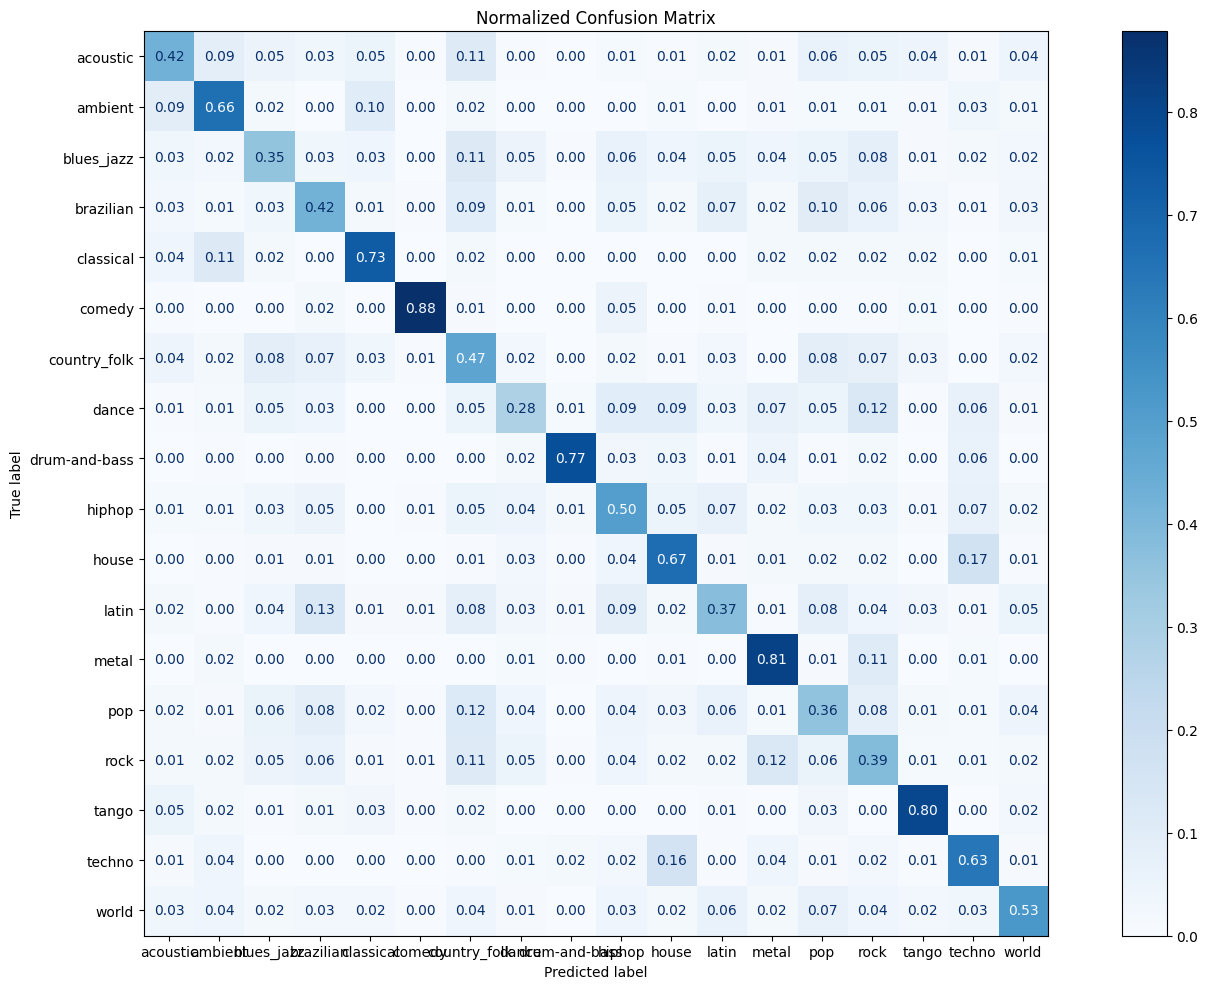

In [32]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(15, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred,
    labels=range(len(y_encoder.classes_)),
    display_labels=y_encoder.classes_,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    ax=ax,

)

ax.set_title("Normalized Confusion Matrix")
plt.tight_layout()
plt.show()

In [33]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

print("Accuracy:", accuracy_score(y_test, pred))
print("F1:", f1_score(y_test, pred, average="macro"))

print(
    classification_report(
        y_test,
        pred,
        target_names=y_encoder.classes_,
        digits=3
    )
)


Accuracy: 0.4823503478212949
F1: 0.5143412840997466
               precision    recall  f1-score   support

     acoustic      0.470     0.423     0.445     11093
      ambient      0.576     0.663     0.616     11512
   blues_jazz      0.457     0.353     0.398     19723
    brazilian      0.443     0.421     0.432     17760
    classical      0.671     0.730     0.699     12330
       comedy      0.757     0.878     0.813      3178
 country_folk      0.371     0.475     0.417     18353
        dance      0.483     0.283     0.357     18480
drum-and-bass      0.572     0.774     0.658      2006
       hiphop      0.480     0.500     0.490     15572
        house      0.384     0.670     0.488      6484
        latin      0.381     0.374     0.378     11445
        metal      0.551     0.814     0.657     12839
          pop      0.396     0.357     0.375     19215
         rock      0.553     0.387     0.456     36655
        tango      0.405     0.796     0.537      2968
       techn

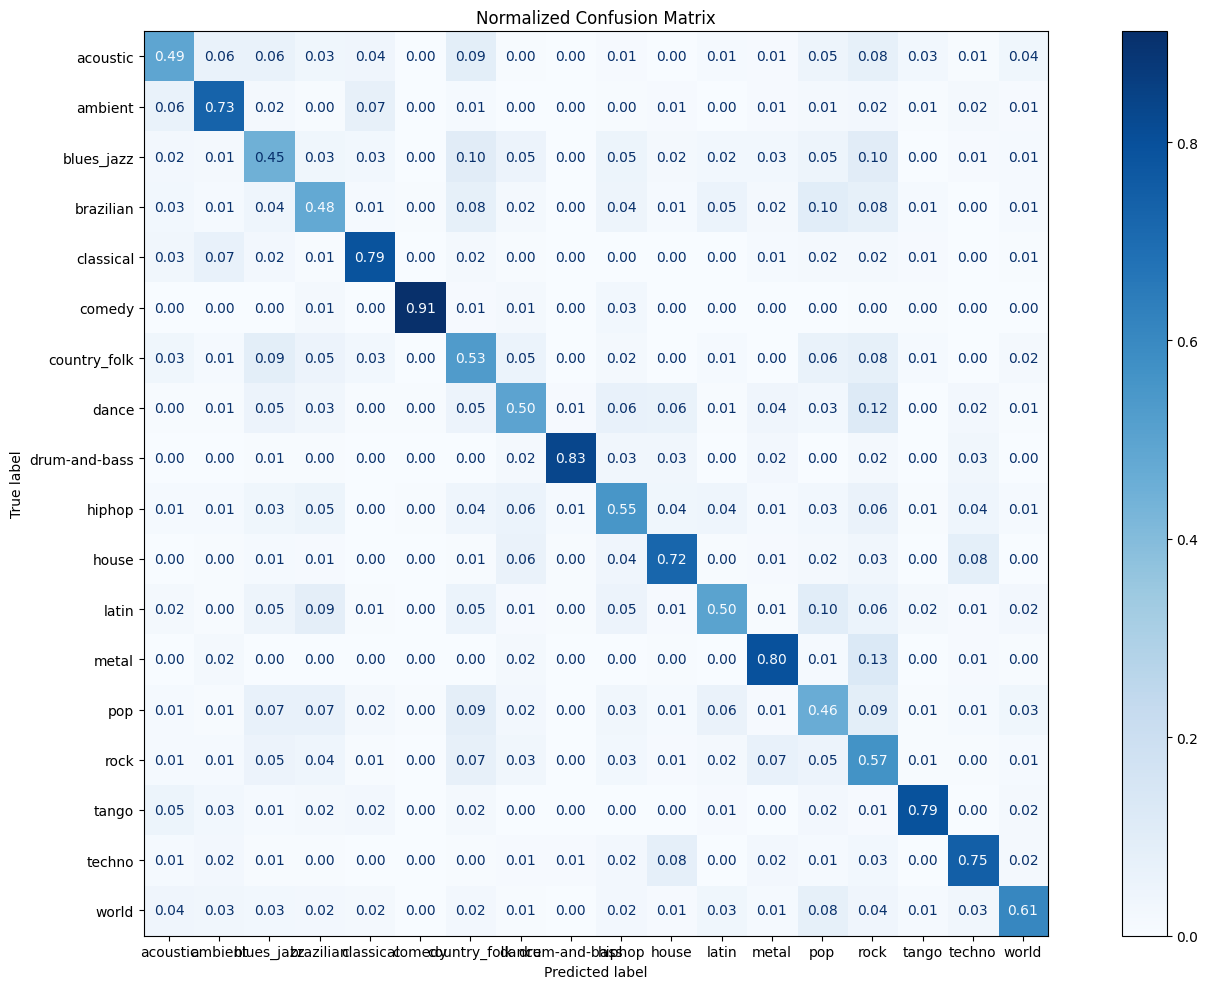

In [ ]:
# kgb
fig, ax = plt.subplots(figsize=(15, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_model.predict(X_test.select(numeric_cols)),
    labels=range(len(y_encoder.classes_)),
    display_labels=y_encoder.classes_,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    ax=ax,

)

ax.set_title("Normalized Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report
pred = xgb_model.predict(X_test.select(numeric_cols))
print("Accuracy:", accuracy_score(y_test, pred))
print("F1:", f1_score(y_test, pred, average="macro"))

print(
    classification_report(
        y_test,
        pred,
        target_names=y_encoder.classes_,
        digits=3
    )
)

Accuracy: 0.5785448733981357
F1: 0.6155964701994924
               precision    recall  f1-score   support

     acoustic      0.552     0.489     0.519     11093
      ambient      0.680     0.732     0.705     11512
   blues_jazz      0.489     0.449     0.468     19723
    brazilian      0.530     0.476     0.501     17760
    classical      0.738     0.788     0.762     12330
       comedy      0.855     0.912     0.882      3178
 country_folk      0.456     0.528     0.489     18353
        dance      0.613     0.498     0.550     18480
drum-and-bass      0.711     0.831     0.766      2006
       hiphop      0.574     0.551     0.562     15572
        house      0.534     0.719     0.613      6484
        latin      0.542     0.500     0.520     11445
        metal      0.662     0.796     0.723     12839
          pop      0.478     0.461     0.469     19215
         rock      0.597     0.565     0.581     36655
        tango      0.572     0.792     0.664      2968
       techn